# Variant analysis

Most variants linked to disease or to a trait lie outside genes. They change
how genes are regulated, often by weakening or destroying a site a
transcription factor binds, or by creating a new one.

This guide follows the variants of a public database through the β-globin
locus. Its promoters hold some of the best understood regulatory variants in
human genetics. Some cause β-thalassemia by silencing *HBB*, the adult
β-globin gene. Others keep the fetal globin genes *HBG1* and *HBG2* switched
on in adults, a harmless condition called hereditary persistence of fetal
hemoglobin (HPFH).

We score each variant against the motifs of a database and look at
insertions and deletions. We then set the sites beside what a model of
chromatin accessibility relies on, and prepare the variants for such a
model.

In [1]:
import pathlib
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(16);

## Downloading the data

We need three files:

- a release of ClinVar, NCBI's database of variants and their clinical
  significance, as a VCF file of about 200 MB;
- human chromosome 11 from the UCSC Genome Browser, in the hg38 assembly
  that ClinVar's positions refer to;
- the JASPAR 2024 collection of vertebrate motifs.

A small helper downloads each file once into a cache directory in your home
folder. ClinVar is updated every week, so we take a dated release from its
archive to keep the results the same:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

clinvar_path = fetch("https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20261101.vcf.gz")
chr11_path = fetch("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr11.fa.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

## Reading variants

[`read_vcf()`][universalmotif.read_vcf] reads the variants of a VCF file into
a table, with one row per alternative allele. Positions are counted from 0,
as everywhere else in the package, so they are one less than in the file:

In [3]:
clinvar = um.read_vcf(clinvar_path)
print(clinvar.height)
clinvar.head(3)

4616247


chrom,position,id,ref,alt,qual,filter,info
str,i64,str,str,str,f64,str,str
"""1""",66925,"""3385321""","""AG""","""A""",null,null,"""ALLELEID=3544463…"
"""1""",69133,"""2205837""","""A""","""G""",null,null,"""ALLELEID=2193183…"
"""1""",69240,"""4562067""","""C""","""T""",null,null,"""ALLELEID=4679177…"


ClinVar keeps its annotations in the `info` column as `KEY=value` pairs.
They include the gene a variant lies in, its clinical significance and its
kind, and polars can pull them out with a regular expression. ClinVar also
names chromosomes `11` where the UCSC Genome Browser names them `chr11`. The
two must agree, so we rename them as we keep the variants of the β-globin
locus:

In [4]:
def info(key):
    return pl.col("info").str.extract(f"{key}=([^;]+)")

variants = (
    clinvar.filter(pl.col("chrom") == "11", pl.col("position").is_between(5_220_000, 5_300_000))
    .with_columns(
        chrom=pl.lit("chr11"),
        gene=info("GENEINFO").str.extract("^([^:]+)"),
        significance=info("CLNSIG"),
        kind=info("CLNVC"),
    )
    .drop("qual", "filter", "info")
)
print(variants.height)
variants.group_by("kind").len().sort("len", descending=True)

2106


kind,len
str,u32
"""single_nucleotid…",1767
"""Deletion""",207
"""Duplication""",69
"""Indel""",27
"""Insertion""",21
"""Microsatellite""",14
"""Inversion""",1


Most of the variants are single-letter substitutions. About 340 change the
length of the sequence, as deletions, insertions, duplications or
combinations of them. Many change the protein itself, and we come to those in
the promoters below.

The variants are scored on the genome they were called on. A whole genome can
be opened with [`Genome`][universalmotif.Genome], which reads only the letters
around each variant. Here a single chromosome is enough, so
[`read_fasta()`][universalmotif.read_fasta] reads it into memory as a mapping
from its name to its sequence:

In [5]:
genome = um.read_fasta(chr11_path)
{name: len(seq) for name, seq in genome.items()}

{'chr11': 135086622}

## Scoring variants

[`variant_motif_effects()`][universalmotif.variant_motif_effects] scores every
window of each motif's width that a variant changes. It scores both the
reference sequence and the sequence with the variant, and keeps the windows
that reach the P-value cutoff in either. We name the JASPAR motifs after their
transcription factors and score all of the locus's variants against them:

In [6]:
jaspar = [m.replace(name=m.altname) for m in um.read_meme(jaspar_path)]
effects = um.variant_motif_effects(variants, genome, jaspar, pvalue=1e-4, nthreads=2)
print(effects.height)
effects.head(3)

/var/folders/js/43k8l5r12hnc6s1c42f5b23w000ghn/T/ipykernel_96044/2699806964.py:2: UserWarning: 98 motifs cannot reach a P-value of 0.0001 and will have no hits; the smallest P-value each can give is: Arnt (0.000244), ZNF354C (0.000244), Arid3a (0.000244), Foxn1 (0.000244), ARNT::HIF1A (0.000977) and 93 more
  effects = um.variant_motif_effects(variants, genome, jaspar, pvalue=1e-4, nthreads=2)


21562


variant,chrom,position,ref,alt,id,motif,start,end,strand,ref_score,alt_score,delta,ref_pvalue,alt_pvalue
u32,str,i64,str,str,str,str,i64,i64,str,f64,f64,f64,f64,f64
0,"""chr11""",5224301,"""GATTTCTTTAAAAATT…","""G""","""1048666""","""NR1H2::RXRA""",5224688,5224705,"""-""",5.952,null,null,0.000031,null
0,"""chr11""",5224301,"""GATTTCTTTAAAAATT…","""G""","""1048666""","""NR1H2::RXRA""",5226698,5226715,"""-""",3.858,null,null,0.000068,null
0,"""chr11""",5224301,"""GATTTCTTTAAAAATT…","""G""","""1048666""","""Znf423""",5226707,5226722,"""-""",10.253,null,null,0.000051,null


The warning names the motifs too short or too degenerate to reach a P-value
of 1e-4. They can have no sites here, and we come back to them below.

Each row of the table is a site that a variant changes. It is numbered by the
variant's row in the table of variants, and gives the site's score and
P-value in both sequences. `delta` is the change in score.

Insertions and deletions also make sites that one of the two sequences lacks:

- a deletion takes away every site that starts in the letters it removes;
- an insertion adds every site that starts in the letters it inserts.

Such sites get a missing score in the other sequence, and a missing `delta`.
Large deletions and duplications remove or add many sites at once, so they
make up much of the table:

In [7]:
(
    effects.join(variants.with_row_index("variant").select("variant", "kind"), on="variant")
    .group_by("kind")
    .agg(
        variants=pl.col("variant").n_unique(),
        sites=pl.len(),
        lost=pl.col("alt_score").is_null().sum(),
        made=pl.col("ref_score").is_null().sum(),
    )
    .sort("sites", descending=True)
)

kind,variants,sites,lost,made
str,u32,u32,u32,u32
"""Deletion""",181,10575,9844,0
"""single_nucleotid…",1478,6331,29,0
"""Duplication""",62,3488,0,3260
"""Indel""",20,1042,899,12
"""Insertion""",18,84,0,18
"""Microsatellite""",11,38,4,2
"""Inversion""",1,4,0,0


## Variants in the promoters

All three genes lie on the minus strand, so their promoters run from the first
transcribed base to higher positions. The distance of a variant upstream of a
gene is its position minus that of the gene's first base. Promoter positions
are usually given this way, so the TATA box of *HBB* lies about 30 bases
upstream, at -30.

The letters of the variants are those of the chromosome's plus strand. They
are the complements of those usually given for these genes, so the -28 A>G of
*HBB* appears here as T>C. We keep the variants of the 250 bases upstream of
each gene:

In [8]:
# The first transcribed base of each gene, counted from 0.
tss = {"HBB": 5_227_070, "HBG1": 5_249_856, "HBG2": 5_254_780}
promoters = variants.with_columns(
    upstream=pl.col("position") - pl.col("gene").replace_strict(tss, default=None)
).filter(pl.col("upstream").is_between(1, 250))
print(promoters.height)
promoters.group_by("gene").len().sort("gene")

85


gene,len
str,u32
"""HBB""",73
"""HBG1""",7
"""HBG2""",5


For each of these variants, the site with the largest change in score shows
the motif it matters most to. The tables of variants and of sites share
ClinVar's identifier of each variant and its alternative allele. Together
these pick out one row of the VCF file, so the two tables can be joined on
them. Here are the variants ClinVar classifies as pathogenic, with sites that
are made or lost outright first:

In [9]:
def strongest(effects, promoters):
    return (
        effects.join(promoters.select("id", "alt", "gene", "upstream", "significance"), on=["id", "alt"])
        .sort(pl.col("delta").abs().fill_null(float("inf")), descending=True)
        .group_by("id", "alt", maintain_order=True)
        .first()
        .sort("gene", "upstream")
    )

columns = ["gene", "upstream", "ref", "alt", "motif", "ref_score", "alt_score", "delta"]
(
    strongest(effects, promoters)
    .filter(pl.col("significance").str.starts_with("Pathogenic"))
    .select(columns)
)

gene,upstream,ref,alt,motif,ref_score,alt_score,delta
str,i64,str,str,str,f64,f64,f64
"""HBB""",25,"""C""","""A""","""Nr2e1""",12.005,4.861,-7.144
"""HBB""",26,"""T""","""G""","""Nr2e1""",12.005,-0.827,-12.832
"""HBB""",27,"""T""","""A""","""Nr2e1""",12.005,6.14,-5.865
"""HBB""",28,"""T""","""C""","""Nr2e1""",12.005,10.69,-1.315
"""HBB""",28,"""T""","""G""","""Nr2e1""",12.005,8.361,-3.644
"""HBB""",29,"""T""","""G""","""TCF7""",7.934,12.802,4.868
"""HBB""",29,"""T""","""C""","""Nr2e1""",12.005,9.458,-2.547
"""HBB""",30,"""A""","""G""","""ZNF449""",11.186,9.688,-1.498
"""HBB""",30,"""A""","""T""","""ZNF449""",11.186,7.418,-3.768


Some of these are the factors we would expect. Every substitution in the
CACCC box of *HBB*, from -86 to -92, destroys a site of the KLF family. Its
member KLF1 activates *HBB* in red blood cells. The variants at -71 and -76
weaken the CCAAT box that NF-Y binds.

Others are harder to read. The variants of the TATA box, from -25 to -31, are
put down to factors such as Nr2e1, ZNF449 and TCF7 rather than to TBP, the
protein that binds the TATA box. In the *HBG* promoters, the largest changes
are to motifs of a nuclear receptor and of zinc finger proteins with long,
GC-rich motifs. With nearly 900 motifs, almost any change touches some site
at this cutoff. The largest change is often to a site of a factor that is not
even made in red blood cells.

## A focused set of factors

The factors known to act on these promoters have motifs of their own, and some
are short. The smallest P-value a motif can give, that of its best possible
site, shows how far a strict cutoff can reach:

In [10]:
factors = ["TBP", "NFYB", "KLF1", "SP1", "GATA1", "TAL1::TCF3", "BCL11A", "ZBTB7A"]
focus = [m for m in jaspar if m.name in factors]
pl.DataFrame({
    "motif": [m.name for m in focus],
    "consensus": [m.consensus for m in focus],
    "best_pvalue": [um.motif_pvalue(m, score=um.motif_range(m)[1]) for m in focus],
})

motif,consensus,best_pvalue
str,str,f64
"""SP1""","""GGGGMGGRG""",0.000004
"""BCL11A""","""CTGACCA""",0.000061
"""GATA1""","""CTWATCT""",0.000061
"""KLF1""","""GGGYGKGG""",0.000015
"""NFYB""","""YCATTGGCC""",0.000004
"""TAL1::TCF3""","""AMCATMTGKT""",9.5367e-7
"""ZBTB7A""","""CCGGAAGTG""",0.000004
"""TBP""","""TATAWAW""",0.000061


The motifs of TBP, BCL11A and GATA1 are only seven letters long. Even their
best sites have P-values of about 6e-5, and the TATA box of *HBB*, a good but
imperfect match, falls short of 1e-4. With a handful of motifs there are far
fewer windows to test, so a looser cutoff of 1e-3 is reasonable. We score the
promoter variants against these factors alone:

In [11]:
focus_effects = um.variant_motif_effects(promoters, genome, focus, pvalue=1e-3)
(
    strongest(focus_effects, promoters)
    .filter(pl.col("significance").str.starts_with("Pathogenic"))
    .select(columns)
)

gene,upstream,ref,alt,motif,ref_score,alt_score,delta
str,i64,str,str,str,f64,f64,f64
"""HBB""",26,"""T""","""G""","""TBP""",9.112,2.487,-6.625
"""HBB""",27,"""T""","""A""","""TBP""",9.112,3.264,-5.848
"""HBB""",28,"""T""","""C""","""TBP""",9.112,-0.955,-10.067
"""HBB""",28,"""T""","""G""","""TBP""",9.112,-0.955,-10.067
"""HBB""",29,"""T""","""G""","""TBP""",9.112,-1.356,-10.468
"""HBB""",29,"""T""","""C""","""TBP""",9.112,3.036,-6.076
"""HBB""",30,"""A""","""C""","""TBP""",9.112,1.735,-7.377
"""HBB""",30,"""A""","""T""","""TBP""",9.112,2.266,-6.846
"""HBB""",30,"""A""","""G""","""TBP""",9.112,3.923,-5.189


Now every substitution of the TATA box weakens TBP's site. The variants of
the CACCC box destroy KLF1's site, and the one at -76 weakens NF-Y's.

The *HBG* promoters tell the story of HPFH. The substitutions at -114 and -117
fall in the distal CCAAT box. There the site of BCL11A, the repressor that
silences the fetal globin genes after birth, overlaps that of NF-Y, and both
are weakened. The table shows whichever changes most. With BCL11A's site
weakened, the genes are no longer silenced.

The variants at -175 and -198 work the other way. The first turns a weak
match to TAL1 and its partner TCF3 into a strong one. The second creates a
GC-rich site that KLF1 and SP1 could bind. Both kinds of factor bring in
activators.

One cutoff does not suit every motif. When a few factors are known to matter,
scoring those, at a cutoff their motifs can reach, says much more than the
whole database.

## Insertions and deletions

The promoters hold a few insertions and deletions too. Two kinds of site are
the same in both sequences and can be compared directly: those that start
before a variant, and those that start at the same letter of both alleles.
Sites that start in letters only one allele has are made or lost outright:

In [12]:
(
    focus_effects.join(promoters.select("id", "alt", "gene", "upstream"), on=["id", "alt"])
    .filter(pl.col("ref").str.len_chars() != pl.col("alt").str.len_chars())
    .sort("gene", "upstream")
    .select(columns[:5] + ["start", "strand", "ref_score", "alt_score", "delta"])
)

gene,upstream,ref,alt,motif,start,strand,ref_score,alt_score,delta
str,i64,str,str,str,i64,str,f64,f64,f64
"""HBB""",25,"""CTT""","""C""","""TBP""",5227096,"""-""",9.112,null,null
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""SP1""",5227123,"""-""",-6.652,2.987,9.639
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""SP1""",5227124,"""-""",-2.824,6.815,9.639
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""KLF1""",5227124,"""-""",-4.961,4.679,9.64
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""KLF1""",5227134,"""+""",7.736,null,null
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""KLF1""",5227156,"""+""",12.649,null,null
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""KLF1""",5227171,"""+""",4.631,null,null
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""NFYB""",5227140,"""+""",10.685,null,null
"""HBB""",59,"""CTCCTGGGAGTAGATT…","""C""","""NFYB""",5227203,"""+""",8.135,null,null


The deletion of two letters of the TATA box at -25 removes the start of
TBP's site. The site is lost, with no score in the sequence with the
deletion.

The deletion of 126 letters starting at -60 takes out the CCAAT box and the
CACCC box together, so the sites of NF-Y and KLF1 there are lost too. A few
windows that start before it now read into the sequence beyond, and score a
little higher.

The insertion of a single C at -86 shifts the rest of the CACCC box by one
letter. KLF1's site starts before the insertion, so it now reads across it,
with a score far below that of any real site.

## Drawing variants along a promoter

[`plot_variant_effects()`][universalmotif.plot_variant_effects] draws variants
as lollipops along a sequence, with the sites of the motifs as arrows
beneath. It takes any effect for each variant, such as a model's predictions.
Here we give it the change in score of each variant's strongest site along
the promoter of *HBG1*:

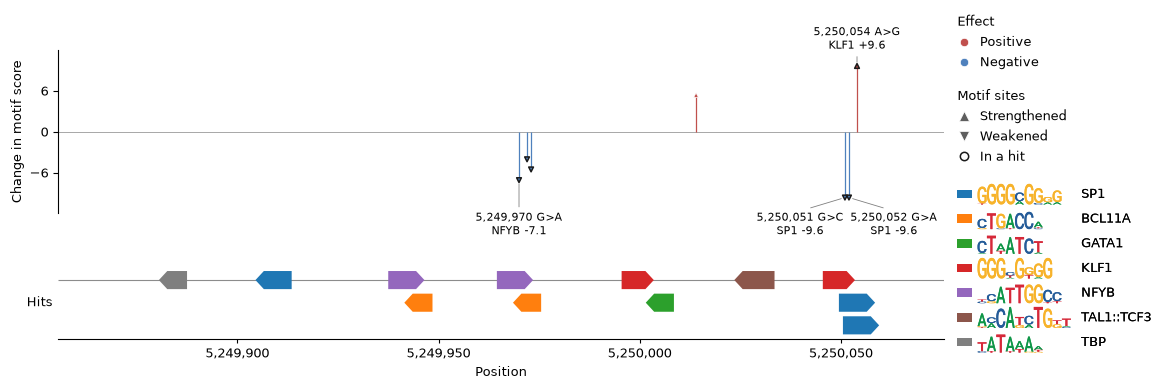

In [13]:
def draw_promoter(gene):
    a = tss[gene]
    shown = (
        strongest(focus_effects, promoters)
        .filter(pl.col("gene") == gene, pl.col("delta").is_not_null())
        .select("position", "ref", "alt", effect="delta")
    )
    return um.plot_variant_effects(
        shown, sequence=genome["chr11"][a:a + 220], motifs=focus, start=a, pvalue=1e-3,
        ylabel="Change in motif score", labels=4, figsize=(10, 4),
    )

fig = draw_promoter("HBG1")

The axis runs along the chromosome, so upstream is to the right. Each arrow
beneath is a site in the reference sequence:

- the TATA box near -30;
- the two CCAAT boxes at about -85 and -115, each overlapping a match to
  BCL11A;
- the CACCC box with KLF1's site near -145;
- GC-rich sites near -200.

The variant at -198 rises above zero where there was no site before. The
promoter of *HBG2* is a near copy of this one, and `draw_promoter("HBG2")`
draws its variants the same way.

## What a model relies on

Sequence models of chromatin accessibility, such as ENCODE's chromBPNet
models, learn which bases make a region open or closed. Their contribution
scores give the share of each base in a prediction, as the
[motifs and deep learning](deep-learning.ipynb) guide shows. ENCODE keeps the
scores of its model of K562 cells, which make fetal globin, as a bigWig track
that can be read from its server.
[`signal_values()`][universalmotif.signal_values] reads the scores of the
*HBG1* promoter, and [`view_attributions()`][universalmotif.view_attributions]
draws them with the sites of the focused motifs above:

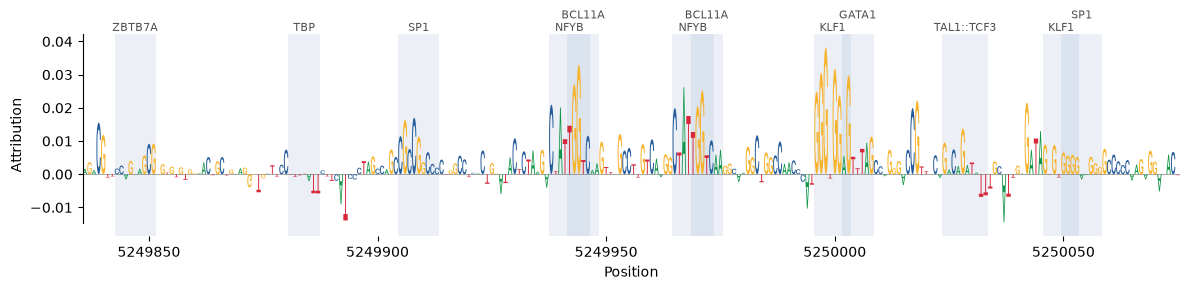

In [14]:
scores_url = "https://www.encodeproject.org/files/ENCFF407GCO/@@download/ENCFF407GCO.bigWig"
a = tss["HBG1"] - 20
b = a + 240
scores = um.signal_values(scores_url, "chr11", a, b)
promoter = genome["chr11"][a:b]
hits = um.scan_sequences(focus, promoter, pvalue=1e-3, no_overlaps=True)
ax = um.view_attributions(scores, promoter, start=a, hits=hits, figsize=(12, 3))

The model relies most on the CACCC box near -145 and on the two CCAAT boxes.
The HPFH variants at -114 to -117, at 5,249,970 to 5,249,973 on the axis,
fall on bases it weighs heavily. The weak TAL1 match near -170 contributes
almost nothing, and the variant at -198 lies on bases of middling weight.

This is what we should expect. The sites these variants make or strengthen
are barely there in the reference sequence, so the reference's scores cannot
show them. To see what such a variant does, the model has to be given the
sequence with the variant.

## Variants for a model

[`variant_batches()`][universalmotif.variant_batches] reads the reference and
alternative sequences around each variant from the genome. They come one-hot
encoded, in batches of the width a model takes. Each window has the variant's
first reference letter in its middle. The alternative sequence keeps the
letters before it, so an insertion pushes letters off the right end and a
deletion pulls more in. With a narrow window and
[`from_one_hot()`][universalmotif.from_one_hot], we can read the sequences of
the deletion at -25 of *HBB* and the insertion at -86:

In [15]:
shown = promoters.filter(
    pl.col("gene") == "HBB", pl.col("upstream").is_in([25, 86]),
    pl.col("ref").str.len_chars() != pl.col("alt").str.len_chars(),
)
ref, alt = next(iter(um.variant_batches(genome, shown, width=21)))
for r, a, (pos, ra, aa) in zip(um.from_one_hot(ref), um.from_one_hot(alt),
                               shown.select("position", "ref", "alt").iter_rows()):
    print(f"{pos} {ra}>{aa}\n  {r}\n  {a}")

5227095 CTT>C
  TCTGCCCTGACTTTTATGCCC
  TCTGCCCTGACTTATGCCCAG
5227156 G>GC
  GCCAACCCTAGGGTGTGGCTC
  GCCAACCCTAGCGGTGTGGCT


The deletion of TT at -25 pulls two more letters in at the right end, and the
insertion of a C at -86 pushes one off it.

A model such as chromBPNet takes windows of 2,114 bases and predicts how
accessible each is. The difference between its predictions for the two
sequences is the variant's effect. We don't have the model here, so this code
is not run. `model` stands for a function that takes a batch of one-hot
sequences and returns a prediction for each, such as chromBPNet's predicted
log counts:

```python
effects = []
for ref, alt in um.variant_batches(genome, promoters, width=2114, batch_size=64):
    effects.append(model(alt) - model(ref))
promoters = promoters.with_columns(effect=np.concatenate(effects))
```

Many models are trained on both strands. Averaging their predictions for a
sequence and its reverse complement steadies the effects; for a batch `x`
with the letters in ACGT order, the reverse complement is `x[:, ::-1, ::-1]`.
The effects can then be drawn with `plot_variant_effects()` as above, with
the motif sites beneath, to read a variant's effect against the sites it
changes. The [experiments on a model](model-experiments.ipynb) guide covers
other ways to question a model with changed sequences.

## From the command line

The `variants` command does the same scoring on a VCF file and a genome, and
writes the table of sites. Here the focused motifs were first written to a
file. The chromosomes of the VCF file and the genome must have the same
names, as they do for most variant callers and the genome they were called
on:

```sh
umotif variants focus.meme -v calls.vcf.gz -g hg38.2bit -P 1e-3 -o variant_sites.tsv
```